In [2]:
# 1. Install libraries
!pip install -q timm grad-cam datasets scikit-learn

import io
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset
import timm
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- CRITICAL FIX: Equalize Resolution, Aspect Ratio & Compression Quality ---
def equalize_image_quality(pil_img, quality=85):
    """
    1. Center-crops to a square (prevents squishing rectangular Real photos vs square AI photos).
    2. Downscales smoothly using LANCZOS anti-aliasing (removes high-res AI aliasing artifacts).
    3. Passes through a standard JPEG buffer so PNG (Fake) and JPEG (Real) have identical compression.
    """
    pil_img = pil_img.convert('RGB')
    # 1 & 2: Center-crop to square and resize smoothly to 224x224
    pil_img = ImageOps.fit(pil_img, (224, 224), method=Image.Resampling.LANCZOS)
    # 3: Standardize JPEG compression across both Real and Fake
    buffer = io.BytesIO()
    pil_img.save(buffer, format="JPEG", quality=quality)
    buffer.seek(0)
    return Image.open(buffer).convert('RGB')

# 2. Stream Dataset and Apply Quality Equalization
print("Fetching Dataset & Equalizing Image Quality (Removing Resolution/PNG Bias)...")
hf_stream = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset", split="train", streaming=True)

train_data, val_data, unseen_test_data = [], [], []

fake_per_model = 300
real_train_val_limit = fake_per_model * 4  # 1,200 Real images to match 1,200 Fake images
real_unseen_limit = fake_per_model         # 300 Real images for unseen test

counts = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0}

for item in hf_stream:
    source_model = item['Label_B'] # 0=Real, 1=SD2.1, 2=SDXL, 3=SD3, 4=DALLE3, 5=Midjourney
    binary_label = item['Label_A'] # 0=Real, 1=Fake

    limit = (real_train_val_limit + real_unseen_limit) if source_model == 0 else fake_per_model

    if counts[source_model] < limit:
        # Equalize quality with random realistic JPEG quality (75 to 95) so model ignores compression!
        q = random.randint(75, 95)
        img = equalize_image_quality(item['Image'], quality=q)
        counts[source_model] += 1

        if source_model == 5 or (source_model == 0 and counts[0] > real_train_val_limit):
            unseen_test_data.append((img, binary_label))
        else:
            if counts[source_model] % 5 == 0:
                val_data.append((img, binary_label))
            else:
                train_data.append((img, binary_label))

    if all(counts[k] >= ((real_train_val_limit + real_unseen_limit) if k == 0 else fake_per_model) for k in counts):
        break

train_reals = sum(1 for _, l in train_data if l == 0)
train_fakes = sum(1 for _, l in train_data if l == 1)

print("Dataset Ready & Quality-Equalized!")
print(f"Balanced Train Set -> REAL: {train_reals} | FAKE: {train_fakes}")
print(f"Balanced Val Set   -> Total: {len(val_data)}")
print(f"Unseen Test Set    -> Total: {len(unseen_test_data)}")

Using device: cuda
Fetching Dataset & Equalizing Image Quality (Removing Resolution/PNG Bias)...


README.md:   0%|          | 0.00/5.37k [00:00<?, ?B/s]

Dataset Ready & Quality-Equalized!
Balanced Train Set -> REAL: 960 | FAKE: 960
Balanced Val Set   -> Total: 480
Unseen Test Set    -> Total: 600


In [3]:
# Define Quality-Invariant Data Augmentations
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomAdjustSharpness(sharpness_factor=2.0)], p=0.4), # Teaches model Real images can be sharp!
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.3),                 # Teaches model Fake images can be blurry!
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CustomImageDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data_list = data_list
        self.transform = transform

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        img, label = self.data_list[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

train_loader = DataLoader(CustomImageDataset(train_data, train_transforms), batch_size=32, shuffle=True)
val_loader = DataLoader(CustomImageDataset(val_data, val_transforms), batch_size=32, shuffle=False)
unseen_loader = DataLoader(CustomImageDataset(unseen_test_data, val_transforms), batch_size=32, shuffle=False)

class_names = ['REAL', 'FAKE']
print("Quality-Invariant DataLoaders Ready!")

Quality-Invariant DataLoaders Ready!


In [4]:
# 1. Load Pretrained Lightweight Vision Transformer
model_name = 'deit_tiny_patch16_224'
model = timm.create_model(model_name, pretrained=True, num_classes=2)

model.head = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(model.head.in_features, 2)
)
model = model.to(device)

# 2. Training Setup
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-2) # Slightly gentler LR (5e-5) preserves pretrained real-world features
epochs = 10
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
best_val_acc = 0.0

# 3. Training Loop (Tracking REAL vs FAKE accuracy separately!)
for epoch in range(epochs):
    model.train()
    train_correct = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_correct += (outputs.argmax(1) == labels).sum().item()

    scheduler.step()
    train_acc = train_correct / len(train_data)

    # Validation
    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            outputs = model(images)
            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_targets.extend(labels.numpy())

    val_preds = np.array(val_preds)
    val_targets = np.array(val_targets)
    val_acc = (val_preds == val_targets).mean()
    real_acc = (val_preds[val_targets == 0] == 0).mean()
    fake_acc = (val_preds[val_targets == 1] == 1).mean()

    print(f"Epoch [{epoch+1:2d}/{epochs}] | Train: {train_acc:.3f} | Val: {val_acc:.3f} (REAL Acc: {real_acc:.3f} | FAKE Acc: {fake_acc:.3f})")

    # Save model that balances both REAL and FAKE best
    balanced_score = min(real_acc, fake_acc)
    if balanced_score >= best_val_acc:
        best_val_acc = balanced_score
        torch.save(model.state_dict(), "best_lightweight_vit.pth")

# 4. Evaluate on UNSEEN Generator (Midjourney)
print("\n--- Testing Generalizability on UNSEEN AI Generator (Midjourney) ---")
model.load_state_dict(torch.load("best_lightweight_vit.pth"))
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in unseen_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch [ 1/10] | Train: 0.667 | Val: 0.863 (REAL Acc: 0.846 | FAKE Acc: 0.879)
Epoch [ 2/10] | Train: 0.849 | Val: 0.879 (REAL Acc: 0.950 | FAKE Acc: 0.808)
Epoch [ 3/10] | Train: 0.914 | Val: 0.921 (REAL Acc: 0.921 | FAKE Acc: 0.921)
Epoch [ 4/10] | Train: 0.947 | Val: 0.910 (REAL Acc: 0.921 | FAKE Acc: 0.900)
Epoch [ 5/10] | Train: 0.960 | Val: 0.927 (REAL Acc: 0.946 | FAKE Acc: 0.908)
Epoch [ 6/10] | Train: 0.979 | Val: 0.929 (REAL Acc: 0.938 | FAKE Acc: 0.921)
Epoch [ 7/10] | Train: 0.985 | Val: 0.938 (REAL Acc: 0.929 | FAKE Acc: 0.946)
Epoch [ 8/10] | Train: 0.986 | Val: 0.931 (REAL Acc: 0.933 | FAKE Acc: 0.929)
Epoch [ 9/10] | Train: 0.988 | Val: 0.929 (REAL Acc: 0.929 | FAKE Acc: 0.929)
Epoch [10/10] | Train: 0.992 | Val: 0.929 (REAL Acc: 0.925 | FAKE Acc: 0.933)

--- Testing Generalizability on UNSEEN AI Generator (Midjourney) ---
              precision    recall  f1-score   support

        REAL     0.7209    0.9300    0.8122       300
        FAKE     0.9014    0.6400    0.74

In [6]:
# 1. Install required libraries
!pip install -q timm grad-cam

import io
import os
import torch
import torch.nn as nn
from torchvision import transforms
import timm
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from google.colab import files
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Rebuild the exact Lightweight Vision Transformer skeleton
model = timm.create_model('deit_tiny_patch16_224', pretrained=False, num_classes=2)
model.head = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(model.head.in_features, 2)
)

# 3. Load your saved .pth file (Updated to match the filename from the training cell)
model_filename = "/content/best_lightweight_vit.pth"
if not os.path.exists(model_filename):
    print("Please upload your downloaded 'best_lightweight_vit.pth' file:")
    uploaded_model = files.upload()
    model_filename = list(uploaded_model.keys())[0]

# 4. Load the trained weights into the model
model.load_state_dict(torch.load(model_filename, map_location=device))
model = model.to(device)
model.eval()
print(f"✅ Successfully loaded '{model_filename}'! Ready to test images.")

# 5. Preprocessing & Quality Equalizer (Matches training pipeline)
def equalize_image_quality(pil_img, quality=85):
    pil_img = pil_img.convert('RGB')
    pil_img = ImageOps.fit(pil_img, (224, 224), method=Image.Resampling.LANCZOS)
    buffer = io.BytesIO()
    pil_img.save(buffer, format="JPEG", quality=quality)
    buffer.seek(0)
    return Image.open(buffer).convert('RGB')

val_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class_names = ['REAL', 'FAKE']

# 6. Setup XAI (Grad-CAM) for Vision Transformer (196 patches -> 14x14 grid)
def reshape_transform(tensor, height=14, width=14):
    result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))
    return result.transpose(2, 3).transpose(1, 2)

target_layers = [model.blocks[-1].norm1]
cam = GradCAM(model=model, target_layers=target_layers, reshape_transform=reshape_transform)

Using device: cuda
✅ Successfully loaded '/content/best_lightweight_vit.pth'! Ready to test images.


Click 'Choose Files' below to upload an image to test:


Saving Golden Retriever Soaring Through Sunlit Clouds.png to Golden Retriever Soaring Through Sunlit Clouds.png

Image File       : Golden Retriever Soaring Through Sunlit Clouds.png
Final Prediction : FAKE (85.48% Confidence)
Class Breakdown  : REAL: 14.52% | FAKE: 85.48%
XAI Explanation  : Highest attention triggered in the [Center-Middle] region.
                   Red/Yellow zones highlight synthetic pixel textures or
                   inconsistent global lighting/geometry detected by ViT.


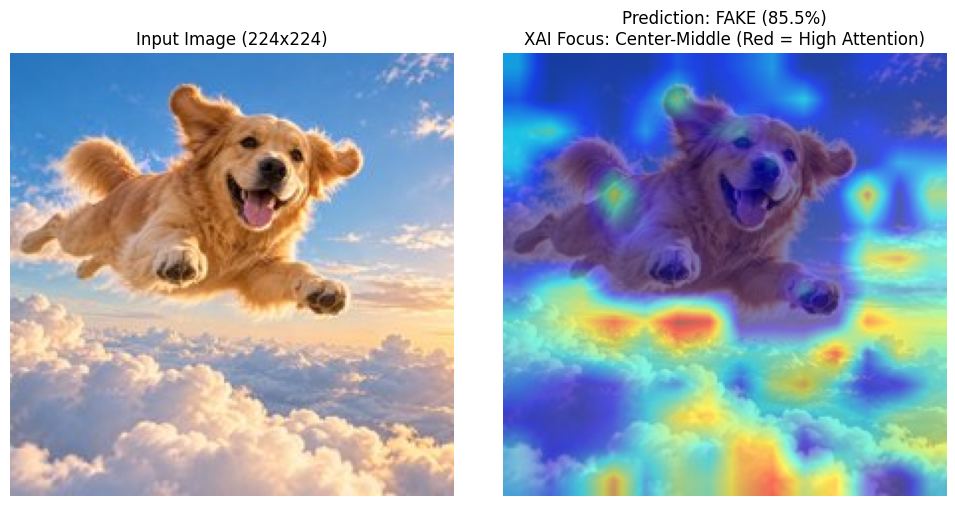

In [7]:
print("Click 'Choose Files' below to upload an image to test:")
uploaded_images = files.upload()

for img_name in uploaded_images.keys():
    # 1. Equalize image quality & convert to tensor
    processed_pil = equalize_image_quality(Image.open(img_name), quality=85)
    rgb_img = np.float32(processed_pil) / 255.0
    input_tensor = val_transforms(processed_pil).unsqueeze(0).to(device)

    # 2. Predict REAL or FAKE
    with torch.no_grad():
        output = model(input_tensor)
        probs = torch.nn.functional.softmax(output, dim=1)
        conf, pred_class = torch.max(probs, 1)

    predicted_label = class_names[pred_class.item()]
    confidence = conf.item() * 100
    real_prob = probs[0][0].item() * 100
    fake_prob = probs[0][1].item() * 100

    # 3. Generate XAI Grad-CAM Heatmap for the predicted class
    targets = [ClassifierOutputTarget(pred_class.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    heatmap_overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # 4. Identify Top Focused Region for Text Reasoning
    max_y, max_x = np.unravel_index(np.argmax(grayscale_cam), grayscale_cam.shape)
    vert_pos = "Top" if max_y < 75 else ("Bottom" if max_y > 150 else "Center")
    horiz_pos = "Left" if max_x < 75 else ("Right" if max_x > 150 else "Middle")

    # 5. Print Forensic Report
    print("\n" + "="*55)
    print(f"Image File       : {img_name}")
    print(f"Final Prediction : {predicted_label} ({confidence:.2f}% Confidence)")
    print(f"Class Breakdown  : REAL: {real_prob:.2f}% | FAKE: {fake_prob:.2f}%")
    print(f"XAI Explanation  : Highest attention triggered in the [{vert_pos}-{horiz_pos}] region.")
    if predicted_label == 'FAKE':
        print("                   Red/Yellow zones highlight synthetic pixel textures or")
        print("                   inconsistent global lighting/geometry detected by ViT.")
    else:
        print("                   Red/Yellow zones highlight consistent natural camera grain")
        print("                   and coherent lighting patterns across image patches.")
    print("="*55)

    # 6. Plot Original vs XAI Reasoning Heatmap
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(processed_pil)
    axes[0].set_title("Input Image (224x224)", fontsize=12)
    axes[0].axis('off')

    axes[1].imshow(heatmap_overlay)
    axes[1].set_title(
        f"Prediction: {predicted_label} ({confidence:.1f}%)\n"
        f"XAI Focus: {vert_pos}-{horiz_pos} (Red = High Attention)",
        fontsize=12
    )
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix (rows = actual, columns = predicted):")
print(cm)